In [ ]:
# 🔁 Version V4 - PINN entraîné sur plusieurs bétons avec temps t comme entrée

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

In [ ]:
# 📥 Charger le dataset
df_all = pd.read_csv("Dataset_multi-temps_format_.csv")
# 📊 Calcul automatique des moyennes et écarts-types
input_columns = ['phi', 'T', 'w_c', 'S0', 't_h']
X_all = df_all[input_columns].drop_duplicates().values.astype(np.float32)
X_mean = tf.constant(np.mean(X_all, axis=0), dtype=tf.float32)
X_std = tf.constant(np.std(X_all, axis=0), dtype=tf.float32)
X_std_safe = tf.where(X_std == 0.0, tf.ones_like(X_std), X_std)
# === 2. Normalisation ===

def normalize(x):
    return (x - X_mean) / X_std_safe

In [ ]:
# === 3. Modèle ANN ===
def build_ann_model(input_dim=5):
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(16, activation='tanh'), # 32 neurones cachés avec activation tanh
        Dense(16, activation='tanh'),
        Dense(1, activation='linear')  # Dv sera activé via softplus ensuite
    ])
    return model

model = build_ann_model()
optimizer = Adam(learning_rate=1e-3)

In [ ]:
@tf.function
def simulate_model_tf(Dv, S0, phi, rho_eau, dx, dt, Tmax, Nx, mode="imbibition"):
    # Convertir tous les scalaires en tf.Tensor
    dx = tf.convert_to_tensor(dx, dtype=tf.float32)
    dt = tf.convert_to_tensor(dt, dtype=tf.float32)
    Tmax = tf.convert_to_tensor(Tmax, dtype=tf.float32)
    Nx = tf.convert_to_tensor(Nx, dtype=tf.int32)

    Nt = tf.cast(tf.math.floordiv(Tmax, dt), tf.int32)
    x_vals = tf.linspace(0.0, dx * tf.cast(Nx - 1, tf.float32), Nx)

    # 🔧 Paramètres physiques
    alpha0 = 0.005
    Sc = 0.8
    nShape = 5
    S_cap = 0.75
    beta = 2.5
    Pc0 = 5e6
    K_in = 1.7e-20
    eta_l = 1e-3

    # ✅ Initialisation de la saturation
    if mode == "imbibition":
        S = tf.ones((Nx,), dtype=tf.float32) * 0.01
        S = tf.tensor_scatter_nd_update(S, [[0]], [S0])
    elif mode == "drainage":
        S = tf.ones((Nx,), dtype=tf.float32) * S0
    else:
        raise ValueError("Mode must be 'imbibition' or 'drainage'")

    M = tf.ones((Nx,), dtype=tf.float32) * dx
    M = tf.tensor_scatter_nd_update(M, [[0], [Nx - 1]], [dx / 2, dx / 2])

    # 📈 Fonctions de diffusion
    def Dvapeur(S_val):
        S_val = tf.clip_by_value(S_val, 1e-4, 1.0)
        fs = alpha0 + (1.0 - alpha0) / (1.0 + tf.pow((1.0 - S_val) / (1.0 - Sc), nShape))
        return tf.clip_by_value(fs, 1e-12, 10.0) * Dv

    def Dcapi(S_val):
        S_val = tf.clip_by_value(S_val, 1e-4, 1.0)
        dpc = -beta * Pc0 * tf.pow(S_val, -beta - 1)
        return tf.abs(dpc) * K_in / eta_l

    def D_S(S_val):
        weight = tf.math.sigmoid(50.0 * (S_val - S_cap))
        return weight * Dcapi(S_val) + (1.0 - weight) * Dvapeur(S_val)

    # 🔁 Boucle temporelle
    for _ in tf.range(Nt):
        S_old = S
        for _ in tf.range(5):  # Picard simplifié
            D_vals = D_S(S)

            D_left = (D_vals[:-1] + D_vals[1:]) / 2.0
            fluxes = D_left * (S[1:] - S[:-1]) / dx

            dS_dt = tf.zeros_like(S)

            # 🌡️ Mise à jour des points intérieurs
            interior_flux = (fluxes[1:] - fluxes[:-1]) / dx
            dS_dt = tf.tensor_scatter_nd_add(
                dS_dt,
                tf.range(1, Nx - 1)[:, tf.newaxis],
                interior_flux
            )

            # ⚠️ Bord droit : Neumann ≈ 0
            last_flux = fluxes[-1] / dx
            dS_dt = tf.tensor_scatter_nd_add(dS_dt, [[Nx - 1]], [-last_flux])

            # 🔁 Mise à jour de S
            S = S_old + dt * dS_dt
            S = tf.tensor_scatter_nd_update(S, [[0]], [S0])  # Dirichlet

    w_final = phi * rho_eau * S
    return x_vals, w_final


In [ ]:
# === 5. Interpolation ===
@tf.function
def tf_linear_interp(x_known, y_known, x_interp):
    x_interp_m = x_interp * 1e-3
    indices = tf.searchsorted(x_known, x_interp_m, side='right') - 1
    indices = tf.clip_by_value(indices, 0, tf.shape(x_known)[0] - 2)
    x0 = tf.gather(x_known, indices)
    x1 = tf.gather(x_known, indices + 1)
    y0 = tf.gather(y_known, indices)
    y1 = tf.gather(y_known, indices + 1)
    return y0 + (y1 - y0) * (x_interp_m - x0) / (x1 - x0 + 1e-12)

In [ ]:
# === 6. Courbes expérimentales ===
x_exp = tf.constant(np.linspace(2, 60, 30), dtype=tf.float32)  # mm
w_exp_all = [tf.constant(np.random.normal(60 - xi, 2.0, size=30), dtype=tf.float32) for xi in x_exp]  # mock

w_exp_mean = tf.reduce_mean(w_exp_all[0])
w_exp_std = tf.math.reduce_std(w_exp_all[0])

In [ ]:
def compute_loss(model, df_all):
    def create_key(df):
        return df.apply(lambda row: f"{row['phi']:.5f}_{row['T']:.1f}_{row['w_c']:.5f}_{row['S0']:.5f}_{int(row['t_h'])}", axis=1)

    if 'key' not in df_all.columns:
        df_all['key'] = create_key(df_all)

    mse_list = []
    skipped = 0

    for key in df_all['key'].unique():
        group = df_all[df_all['key'] == key]
        if group.empty:
            print(f"⚠️ Profil introuvable pour la clé : {key}")
            skipped += 1
            continue

        try:
            # 🔁 Extraire les paramètres du profil
            phi = group['phi'].iloc[0]
            T = group['T'].iloc[0]
            wc = group['w_c'].iloc[0]
            S0 = group['S0'].iloc[0]
            t_h = group['t_h'].iloc[0]

            x_exp = tf.constant(group['x_mm'].values.astype(np.float32))
            w_exp = tf.constant(group['w_exp'].values.astype(np.float32))

            if len(x_exp) == 0:
                print(f"❌ Profil vide pour : {key}")
                skipped += 1
                continue

            w_mean = tf.reduce_mean(w_exp)
            w_std = tf.math.reduce_std(w_exp)

            if w_std.numpy() == 0.0:
                print(f"⚠️ w_exp_std = 0 pour {key}, ignoré")
                skipped += 1
                continue

            # 🔎 Entrée du modèle
            input_tensor = tf.convert_to_tensor([[phi, T, wc, S0, t_h]], dtype=tf.float32)
            norm_input = normalize(input_tensor)

            if tf.reduce_any(tf.math.is_nan(norm_input)):
                print(f"❌ NaN dans l'entrée normalisée, profil {key}")
                skipped += 1
                continue

            D0 = model(norm_input)
            if tf.reduce_any(tf.math.is_nan(D0)):
                print(f"❌ D0 = NaN pour {key}")
                skipped += 1
                continue

            Dv = tf.clip_by_value(tf.squeeze(tf.nn.softplus(D0) * 1e-7), 1e-10, 5e-8)

            x_model, w_model = simulate_model_tf(Dv, S0, phi, 1000.0,
                                                 dx=1e-3, dt=30.0, Tmax=t_h * 3600, Nx=100)

            x_min = tf.reduce_min(x_model)
            x_max = tf.reduce_max(x_model)
            x_exp_clipped = tf.clip_by_value(x_exp * 1e-3, x_min, x_max) * 1e3

            w_interp = tf_linear_interp(x_model, w_model, x_exp_clipped)
            w_interp_norm = (w_interp - w_mean) / (w_std + 1e-12)
            w_exp_norm = (w_exp - w_mean) / (w_std + 1e-12)

            if tf.reduce_any(tf.math.is_nan(w_interp_norm)) or tf.reduce_any(tf.math.is_nan(w_exp_norm)):
                print(f"❌ NaN dans les profils normalisés {key}")
                skipped += 1
                continue

            mse = tf.reduce_mean(tf.square(w_interp_norm - w_exp_norm))
            mse_list.append(mse)

        except Exception as e:
            print(f"🚨 Erreur inattendue dans le profil {key} : {e}")
            skipped += 1
            continue

    if not mse_list:
        print("❌ Aucune donnée exploitable.")
        return tf.constant(float('nan'), dtype=tf.float32)

    print(f"✅ Profils utilisés : {len(mse_list)} / {len(df_all['key'].unique())}, ignorés : {skipped}")
    return tf.reduce_mean(mse_list)


In [ ]:
def debug_all_profiles(model, df_all):
    input_columns = ['phi', 'T', 'w_c', 'S0', 't_h']
    profiles = df_all[input_columns].drop_duplicates().values.astype(np.float32)

    for i, row in enumerate(profiles):
        phi, T, wc, S0, t_h = row
        print(f"\n🔎 Profil {i+1}: phi={phi}, T={T}, wc={wc}, S0={S0}, t_h={t_h}")

        try:
            input_tensor = tf.convert_to_tensor([[phi, T, wc, S0, t_h]], dtype=tf.float32)
            norm_input = normalize(input_tensor)

            # Check normalization
            if tf.math.reduce_any(tf.math.is_nan(norm_input)):
                print("❌ NaN dans l'entrée normalisée !")
                continue

            D0 = model(norm_input)
            if tf.math.reduce_any(tf.math.is_nan(D0)):
                print("❌ D0 prédit est NaN !")
                continue

            Dv = tf.squeeze(tf.nn.softplus(D0) * 1e-7)
            print(f"✅ D0 = {D0.numpy().squeeze():.2e} → Dv = {Dv.numpy():.2e}")

            group = df_all[
                (df_all['phi'] == phi) &
                (df_all['T'] == T) &
                (df_all['w_c'] == wc) &
                (df_all['S0'] == S0) &
                (df_all['t_h'] == t_h)
            ]
            x_exp = tf.constant(group['x_mm'].values.astype(np.float32))
            w_exp = tf.constant(group['w_exp'].values.astype(np.float32))

            w_mean = tf.reduce_mean(w_exp)
            w_std = tf.math.reduce_std(w_exp)

            if w_std.numpy() == 0.0:
                print("⚠️ Écart-type nul pour w_exp !")
                continue

            x_model, w_model = simulate_model_tf(Dv, S0, phi, 1000.0,
                                                 dx=1e-3, dt=30.0, Tmax=t_h*3600, Nx=50)
            w_interp = tf_linear_interp(x_model, w_model, x_exp)
            w_interp_norm = (w_interp - w_mean) / w_std
            w_exp_norm = (w_exp - w_mean) / w_std

            mse = tf.reduce_mean(tf.square(w_interp_norm - w_exp_norm))
            print(f"📉 Loss MSE pour ce profil : {mse.numpy():.4e}")

        except Exception as e:
            print("🚨 Erreur pendant le calcul :", e)


In [ ]:
debug_all_profiles(model, df_all)


In [ ]:
input_tensor = tf.convert_to_tensor([[0.119, 20.0, 0.45, 0.6, 72.0]], dtype=tf.float32)
D0 = model(normalize(input_tensor))
Dv = tf.clip_by_value(tf.squeeze(tf.nn.softplus(D0) * 1e-7), 1e-10, 5e-8)

x_model, w_model = simulate_model_tf(Dv, 0.6, 0.119, 1000.0, dx=1e-3, dt=30.0, Tmax=72*3600, Nx=100)

import matplotlib.pyplot as plt
plt.plot(x_model.numpy()*1000, w_model.numpy(), label="Simulation")
plt.title("Test manuel d’un profil à 72h")
plt.xlabel("x [mm]")
plt.ylabel("w [kg/m³]")
plt.grid()
plt.legend()
plt.show()


In [ ]:
# 🧪 Extraire un seul profil expérimental pour t = 72h (ou 2h ou 24h)
profil_test = df_all[(df_all['t_h'] == 72.0)]

if profil_test.empty:
    print("❌ Aucun profil trouvé pour t_h = 72.0h")
else:
    phi = profil_test['phi'].iloc[0]
    T = profil_test['T'].iloc[0]
    wc = profil_test['w_c'].iloc[0]
    S0 = profil_test['S0'].iloc[0]
    t_h = profil_test['t_h'].iloc[0]

    x_exp = tf.constant(profil_test['x_mm'].values.astype(np.float32))
    w_exp = tf.constant(profil_test['w_exp'].values.astype(np.float32))

    w_mean = tf.reduce_mean(w_exp)
    w_std = tf.math.reduce_std(w_exp)

    print("📊 Taille données exp :", len(x_exp.numpy()), "std:", w_std.numpy())

    if tf.math.is_nan(w_std) or w_std.numpy() == 0.0:
        print("⚠️ w_exp_std = 0 ou NaN, arrêt.")
    else:
        input_tensor = tf.convert_to_tensor([[phi, T, wc, S0, t_h]], dtype=tf.float32)
        input_norm = normalize(input_tensor)

        if tf.reduce_any(tf.math.is_nan(input_norm)):
            print("❌ NaN dans entrée normalisée")
        else:
            D0 = model(input_norm)
            Dv = tf.clip_by_value(tf.squeeze(tf.nn.softplus(D0) * 1e-7), 1e-10, 5e-8)
            print("✅ Dv simulé :", Dv.numpy())

            x_model, w_model = simulate_model_tf(Dv, S0, tf.convert_to_tensor(phi, dtype=tf.float32), 1000.0,
                                                 dx=1e-3, dt=30.0, Tmax=float(t_h)*3600, Nx=100)

            print("📏 x_model range :", x_model.numpy()[0]*1000, "→", x_model.numpy()[-1]*1000)
            print("📏 x_exp range   :", x_exp.numpy()[0], "→", x_exp.numpy()[-1])

            x_exp_clip = tf.clip_by_value(x_exp * 1e-3, x_model[0], x_model[-1]) * 1e3
            w_interp = tf_linear_interp(x_model, w_model, x_exp_clip)

            w_exp_norm = (w_exp - w_mean) / (w_std + 1e-12)
            w_interp_norm = (w_interp - w_mean) / (w_std + 1e-12)

            if tf.reduce_any(tf.math.is_nan(w_interp_norm)):
                print("❌ NaN dans w_interp_norm")
            else:
                loss = tf.reduce_mean(tf.square(w_interp_norm - w_exp_norm))
                print("✅ LOSS TEST =", loss.numpy())

                # 🔍 Plot pour valider visuellement
                import matplotlib.pyplot as plt
                plt.plot(x_model.numpy()*1000, w_model.numpy(), label="Simulation")
                plt.plot(x_exp.numpy(), w_exp.numpy(), 'o', label="Expérimental")
                plt.legend()
                plt.title("Profil test à t = 72h")
                plt.grid()
                plt.show()


In [ ]:
def train_epoch(model, df_all, optimizer, normalize, simulate_model_tf, tf_linear_interp, Nx=50, dx=1e-3, dt=30.0):
    import tensorflow as tf
    import numpy as np

    unique_inputs = (
        df_all[['phi', 'T', 'w_c', 'S0', 't_h']]
        .round(4)
        .drop_duplicates()
        .values.astype(np.float32)
    )

    total_loss = 0.0
    valid_count = 0
    D0_epoch_vals = []

    with tf.GradientTape() as tape:
        for i in range(len(unique_inputs)):
            phi, T, wc, S0, t_h = unique_inputs[i]
            input_tensor = tf.convert_to_tensor([[phi, T, wc, S0, t_h]], dtype=tf.float32)
            D0 = model(normalize(input_tensor))
            Dv = tf.squeeze(tf.nn.softplus(D0) * 1e-7)

            phi_f, T_f, wc_f, S0_f, t_h_f = map(float, [phi, T, wc, S0, t_h])
            group = df_all[
                (df_all['phi'].round(4) == round(phi_f, 4)) &
                (df_all['T'] == T_f) &
                (df_all['w_c'].round(4) == round(wc_f, 4)) &
                (df_all['S0'].round(4) == round(S0_f, 4)) &
                (df_all['t_h'] == t_h_f)
            ]

            x_exp = tf.constant(group['x_mm'].values.astype(np.float32))
            w_exp = tf.constant(group['w_exp'].values.astype(np.float32))

            print(f"\n🔎 Profil {i+1}/{len(unique_inputs)}: phi={phi}, T={T}, wc={wc}, S0={S0}, t_h={t_h}")
            print("📊 Nombre de points trouvés :", len(group))
            print(group[['x_mm', 'w_exp']])

            if len(x_exp) < 3:
                print("❌ Trop peu de points pour profil :", t_h)
                continue

            w_exp_mean = tf.reduce_mean(w_exp)
            w_exp_std = tf.math.reduce_std(w_exp)
            if tf.math.is_nan(w_exp_std) or w_exp_std < 1e-8:
                print(f"❌ Rejeté : std(w_exp) = {w_exp_std.numpy()}")
                continue

            x_model, w_model = simulate_model_tf(Dv, S0, phi, 1000.0, dx, dt, t_h * 3600.0, Nx)
            x_exp_clip = tf.clip_by_value(x_exp * 1e-3, x_model[0], x_model[-1]) * 1e3
            w_interp = tf_linear_interp(x_model, w_model, x_exp_clip)

            w_exp_norm = (w_exp - w_exp_mean) / (w_exp_std + 1e-12)
            w_interp_norm = (w_interp - w_exp_mean) / (w_exp_std + 1e-12)

            if tf.reduce_any(tf.math.is_nan(w_interp_norm)):
                print("❌ Rejeté : NaN dans w_interp_norm")
                continue

            loss = tf.reduce_mean(tf.square(w_interp_norm - w_exp_norm))
            if tf.math.is_nan(loss):
                print("❌ Rejeté : NaN dans le loss")
                continue

            print("✅ Profil accepté. Loss =", loss.numpy())

            total_loss += loss
            valid_count += 1
            D0_epoch_vals.append(D0.numpy()[0][0])

        if valid_count == 0:
            print("❌ Aucun profil valide → arrêt.")
            return None, None

        mean_loss = total_loss / valid_count

    grads = tape.gradient(mean_loss, model.trainable_variables)
    grads = [tf.clip_by_value(g, -1.0, 1.0) if g is not None else None for g in grads]
    optimizer.apply_gradients(zip(grads, model.trainable_variables))

    return mean_loss.numpy(), np.mean(D0_epoch_vals)



🔎 Profil 1/3: phi=0.11900000274181366, T=20.0, wc=0.44999998807907104, S0=0.6000000238418579, t_h=2.0
📊 Nombre de points trouvés : 6
    x_mm  w_exp
0   1.77  68.63
1   5.37  63.79
2   7.02  57.91
3   8.08  27.06
4  10.21  11.11
5  11.74   0.52
✅ Profil accepté. Loss = 1.8622742

🔎 Profil 2/3: phi=0.11900000274181366, T=20.0, wc=0.44999998807907104, S0=0.6000000238418579, t_h=24.0
📊 Nombre de points trouvés : 6
     x_mm  w_exp
6    2.06  70.20
7   29.91  52.42
8   31.68  44.05
9   33.92  19.48
10  35.22   5.36
11  37.94   0.52
✅ Profil accepté. Loss = 1.2316046

🔎 Profil 3/3: phi=0.11900000274181366, T=20.0, wc=0.44999998807907104, S0=0.6000000238418579, t_h=72.0
📊 Nombre de points trouvés : 19
     x_mm  w_exp
12   1.95  67.32
13   8.08  68.24
14  16.46  64.97
15  19.88  65.23
16  22.48  65.23
17  26.49  63.66
18  28.61  66.80
19  31.80  64.58
20  33.92  62.48
21  35.69  59.08
22  45.60  54.25
23  47.85  48.10
24  50.44  36.47
25  40.29  59.08
26  43.13  58.04
27  52.21  26.67
28  5

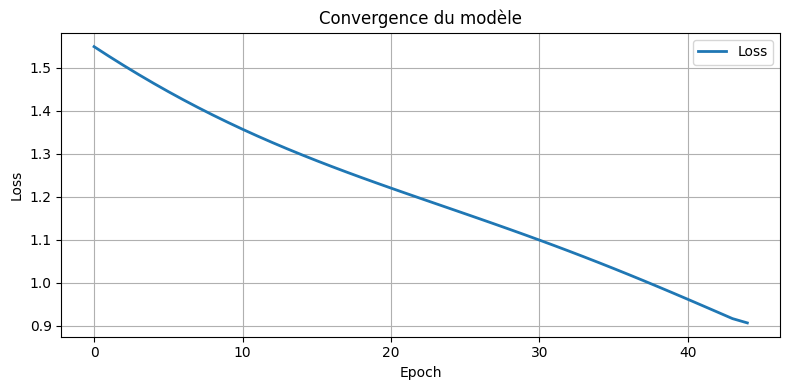

In [169]:
import matplotlib.pyplot as plt
import numpy as np

loss_history = []
D0_history = []

for epoch in range(100):
    mean_loss, mean_D0 = train_epoch(
        model, df_all, optimizer, normalize,
        simulate_model_tf, tf_linear_interp,
        Nx=50, dx=1e-3, dt=30.0
    )

    if mean_loss is None:
        print(f"Epoch {epoch}: ❌ Aucun profil valide → entraînement arrêté.")
        break

    loss_history.append(mean_loss)
    D0_history.append(mean_D0)

    if epoch % 10 == 0:
        print(f"📉 Epoch {epoch}, Loss: {mean_loss:.4e}, D0 mean: {mean_D0:.4e}")
        model.save_weights(f"model_checkpoint_epoch{epoch}.weights.h5")  # 💾 Sauvegarde du modèle
        np.save("loss_history.npy", loss_history)
        np.save("D0_history.npy", D0_history)

# 🎯 Graphe de convergence
plt.figure(figsize=(8, 4))
plt.plot(loss_history, label="Loss", linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Convergence du modèle")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
Dv_test = tf.constant(1e-8, dtype=tf.float32)
x_model, w_model = simulate_model_tf(Dv_test, 0.6, 0.119, 1000.0, dx=1e-3, dt=30.0, Tmax=72*3600, Nx=100)

print("x_model (mm):", x_model.numpy() * 1000)
print("w_model:", w_model.numpy())


In [ ]:
print("x_exp (mm):", x_exp.numpy())
print("x_exp range:", tf.reduce_min(x_exp).numpy(), "→", tf.reduce_max(x_exp).numpy())
print("x_model range:", x_model.numpy()[0] * 1000, "→", x_model.numpy()[-1] * 1000)


📂 Chargement du modèle depuis : model_checkpoint_epoch40.weights.h5


C:\Users\PC\AppData\Local\Temp\ipykernel_29772\2939205853.py:38: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\PC\AppData\Local\Temp\ipykernel_29772\2939205853.py:38: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
c:\Users\PC\Desktop\hybrid-PINN-LSTM\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\PC\Desktop\hybrid-PINN-LSTM\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


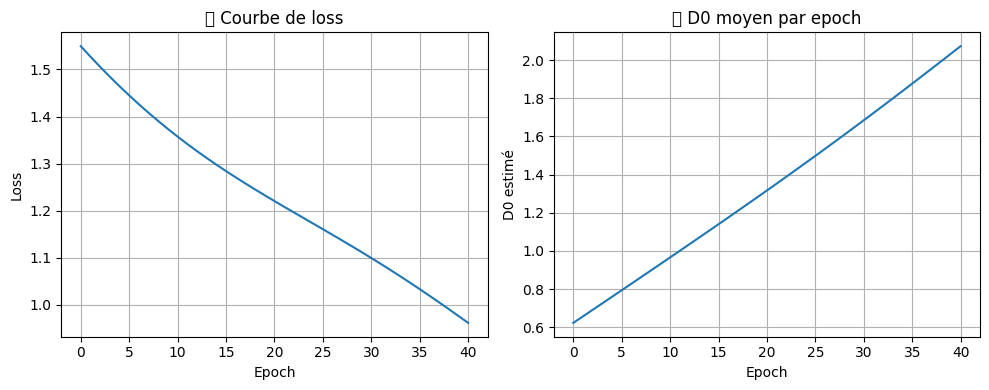

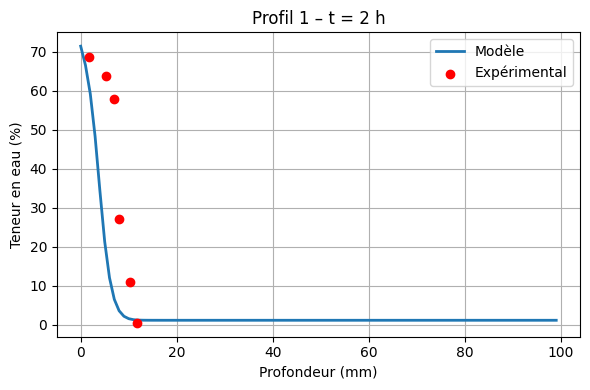

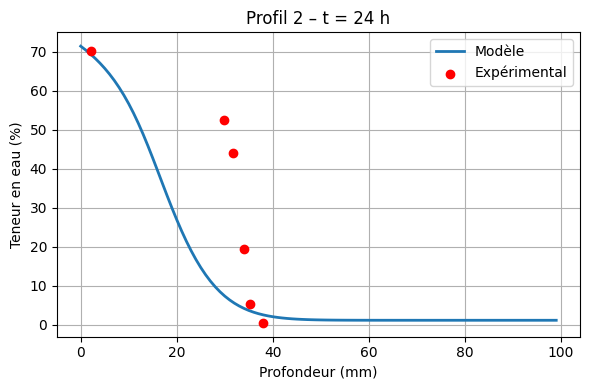

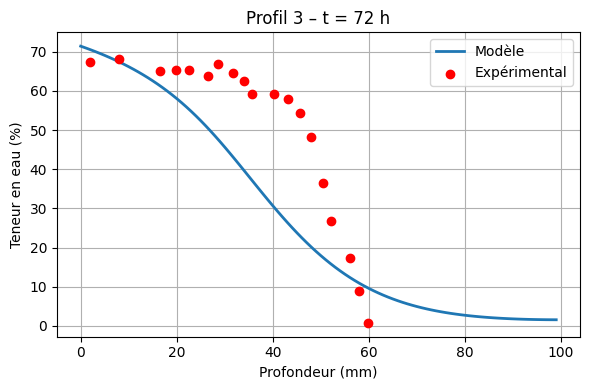

In [171]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# 🔍 Trouver le dernier fichier de poids sauvegardé
checkpoints = [f for f in os.listdir() if f.startswith("model_checkpoint_epoch") and f.endswith(".weights.h5")]
if not checkpoints:
    raise ValueError("❌ Aucun fichier .weights.h5 trouvé.")

# 🔢 Extraire le numéro d'epoch et trier
checkpoints_sorted = sorted(checkpoints, key=lambda x: int(x.split("epoch")[1].split(".")[0]))
last_checkpoint = checkpoints_sorted[-1]
print(f"📂 Chargement du modèle depuis : {last_checkpoint}")

# ✅ Charger les poids
model.load_weights(last_checkpoint)

# 📈 Afficher loss et D0
loss_history = np.load("loss_history.npy")
D0_history = np.load("D0_history.npy")

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(loss_history, label="Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("📉 Courbe de loss")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(D0_history, label="D0 moyen")
plt.xlabel("Epoch")
plt.ylabel("D0 estimé")
plt.title("📈 D0 moyen par epoch")
plt.grid(True)

plt.tight_layout()
plt.show()

# 🔁 Affichage des courbes prédictions vs expérimental
unique_inputs = (
    df_all[['phi', 'T', 'w_c', 'S0', 't_h']]
    .round(4)
    .drop_duplicates()
    .values.astype(np.float32)
)

for i in range(len(unique_inputs)):
    phi, T, wc, S0, t_h = unique_inputs[i]
    input_tensor = tf.convert_to_tensor([[phi, T, wc, S0, t_h]], dtype=tf.float32)
    D0 = model(normalize(input_tensor))
    Dv = tf.squeeze(tf.nn.softplus(D0) * 1e-7)

    group = df_all[
        (df_all['phi'].round(4) == round(float(phi), 4)) &
        (df_all['T'] == float(T)) &
        (df_all['w_c'].round(4) == round(float(wc), 4)) &
        (df_all['S0'].round(4) == round(float(S0), 4)) &
        (df_all['t_h'] == float(t_h))
    ]

    x_exp = tf.constant(group['x_mm'].values.astype(np.float32))
    w_exp = tf.constant(group['w_exp'].values.astype(np.float32))

    if len(x_exp) < 2:
        print(f"⚠️ Profil {i+1}: trop peu de points expérimentaux ({len(x_exp)})")
        continue

    Tmax = float(t_h) * 3600.0
    x_model, w_model = simulate_model_tf(Dv, S0, phi, 1000.0, dx=1e-3, dt=30.0, Tmax=Tmax, Nx=100)

    x_model = x_model.numpy() * 1000  # m → mm
    w_model = w_model.numpy()
    x_exp_np = x_exp.numpy()
    w_exp_np = w_exp.numpy()

    plt.figure(figsize=(6, 4))
    plt.plot(x_model, w_model, label="Modèle", linewidth=2)
    plt.scatter(x_exp_np, w_exp_np, color='red', label="Expérimental", zorder=5)
    plt.xlabel("Profondeur (mm)")
    plt.ylabel("Teneur en eau (%)")
    plt.title(f"Profil {i+1} – t = {int(t_h)} h")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()


In [ ]:
try:
    input_tensor = tf.convert_to_tensor([[phi, T, wc, S0, t_h]], dtype=tf.float32)
    D0 = model(normalize(input_tensor))
    Dv = tf.nn.softplus(D0)[0][0].numpy() * 1e-7
    Tmax = float(t_h) * 3600

    x_model, w_model = simulate_model_tf(Dv, S0, phi, 1000.0, dx=1e-3, dt=30.0, Tmax=Tmax, Nx=100)
    x_model = x_model.numpy() * 1000
    w_model = w_model.numpy()

    print("✅ Dv:", Dv)
    print("📏 x_model range:", x_model[0], "→", x_model[-1])
    print("📏 w_model preview:", w_model[:5])

    plt.figure(figsize=(7, 5))
    plt.scatter(x_exp, w_exp, color='red', label='Expérimental', zorder=5)
    plt.plot(x_model, w_model, color='blue', label='Simulation')
    plt.title(f"Simulation vs Données (t_h = {t_h}h)")
    plt.xlabel("Profondeur (mm)")
    plt.ylabel("Teneur en eau (kg/m³)")
    plt.legend()
    plt.grid(True)
    plt.show()

except Exception as e:
    print("❌ Erreur dans l’affichage :", e)
